#### **Predictive Modelling for Dual-Fuel Engine Performance and Emissions Optimization**

##### **Purpose:** This notebook trains and evaluates surrogate machine learning models to predict Brake Thermal Efficiency (BTE) and exhaust emissions (BSNOX, BSCO2, BSTHC) based on engine load and methanol substitution ratios. It compares algorithms like Gradient Boosting, Random Forest, and Gaussian Process Regression using Leave-One-Out Cross-Validation (LOOCV) to select the optimal models for the interactive ML web app.

##### **Dataset Overview:**  The dataset consists of steady-state operating points from a heavy-duty natural gas engine modified with a methanol port-injection system. The data points cover light, medium, and heavy loads (BMEP of 0.387, 0.775, and 1.163 MPa) at a constant engine speed of 1600 rpm and an excess air ratio of 1.3. The data used was the research dataset from the published work *"Experimental investigation on performance and combustion characteristics of spark-ignition dual-fuel engine fueled with methanol/natural gas"* by Chen et al. (2019).

##### **Author:** Bello Oluwatobi

##### **Last Updated:** October 15, 2026

### #1 Importing libraries and loading processed thermodynamic data

In [1]:
# importing libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.linear_model import Ridge
import joblib

In [2]:
# loading the processed thermodynamic data
df_features = pd.read_csv('data/processed_data.csv')

In [3]:
# loading the raw experimental target emissions
file_path = 'data/Data-for-Experimental investigation on the performance and combustion characteristics.xlsx'
df_perf_raw = pd.read_excel(file_path, sheet_name='Performance Data', skiprows=1)
df_emiss = pd.read_excel(file_path, sheet_name='Emission Data', skiprows=1).dropna(subset=['No.'])


In [4]:
# cleaning the missing BMEP rows and forcing the string columns to numeric
df_perf_raw['BMEP'] = df_perf_raw['BMEP'].ffill()
df_perf_raw = df_perf_raw.dropna(subset=['No.']).reset_index(drop=True)
df_perf_raw['mNG'] = pd.to_numeric(df_perf_raw['mNG'], errors='coerce')
df_perf_raw['mM'] = pd.to_numeric(df_perf_raw['mM'], errors='coerce')

In [5]:
# inspecting the data
df_perf_raw.head()

,No.,Engine speed,BMEP,λ,θig,mNG,mM,Tex,MSR
0,1.0,1600,0.387,1.3,-26,12.34,0.00,544.6,0
1,2.0,NaN,0.387,NaN,NaN,10.81,2.25,542.3,7.7
2,3.0,NaN,0.387,NaN,NaN,10.04,4.12,541.2,14.2
3,4.0,NaN,0.387,NaN,NaN,9.34,5.84,540.7,20.1
4,5.0,NaN,0.387,NaN,NaN,8.84,7.10,540.1,24.4


In [6]:
# calculating the Brake Thermal Efficiency (BTE)

# BMEP: MPa to kPa
bmep_kpa = df_perf_raw['BMEP'] * 1000

# Volume: 9.726 Liters to cubic meters
v_d_m3 = 9.726 / 1000  

# Engine Power (Pe) in kW = BMEP(kPa) * V_d(m^3) * (RPM / 120 for 4-stroke)
df_perf_raw['Pe_kW'] = bmep_kpa * v_d_m3 * (1600 / 120)

# Fuel Energy Rate in kW = (mass_flow_kg_per_s * LHV_kJ_per_kg)
df_perf_raw['Energy_rate_kW'] = (df_perf_raw['mNG'] / 3600) * 50050 + (df_perf_raw['mM'] / 3600) * 20110

# BTE [%]
df_perf_raw['BTE'] = (df_perf_raw['Pe_kW'] / df_perf_raw['Energy_rate_kW']) * 100

In [7]:
# inspecting the newly added columns
df_perf_raw.head()

,No.,Engine speed,BMEP,λ,θig,mNG,mM,Tex,MSR,Pe_kW,Energy_rate_kW,BTE
0,1.0,1600,0.387,1.3,-26,12.34,0.00,544.6,0,50.18616,171.560278,29.252785
1,2.0,NaN,0.387,NaN,NaN,10.81,2.25,542.3,7.7,50.18616,162.857778,30.815943
2,3.0,NaN,0.387,NaN,NaN,10.04,4.12,541.2,14.2,50.18616,162.598667,30.86505
3,4.0,NaN,0.387,NaN,NaN,9.34,5.84,540.7,20.1,50.18616,162.474833,30.888575
4,5.0,NaN,0.387,NaN,NaN,8.84,7.10,540.1,24.4,50.18616,162.561944,30.872022


In [8]:
# cleaning and renaming for merging
df_targets = df_emiss[['No.', 'BSNOX', 'BSTHC', 'BSCO2', 'BSCO']].copy()
df_targets['BTE'] = df_perf_raw['BTE'].values
df_targets.rename(columns={'No.': 'Test_No'}, inplace=True)

In [9]:
# assembling the full ML dataset
df_full = pd.merge(df_features, df_targets, on='Test_No')

### #2 Exploratory Data Analysis

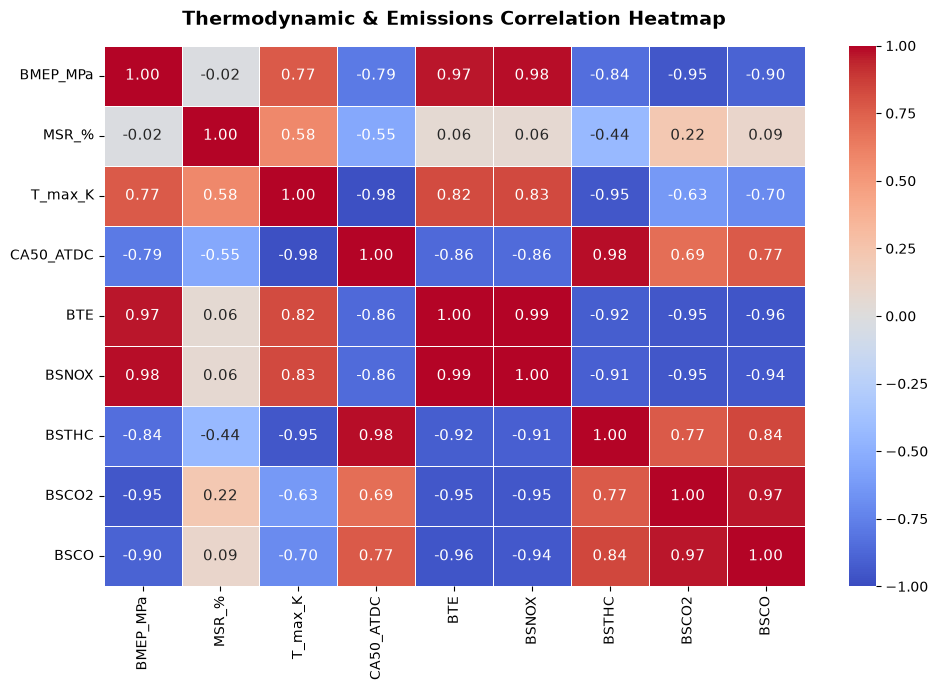

In [10]:
# visualizing the thermodynamic correlation heatmap
cols_for_corr = ['BMEP_MPa', 'MSR_%', 'T_max_K', 'CA50_ATDC', 'BTE', 'BSNOX', 'BSTHC', 'BSCO2', 'BSCO']
plt.figure(figsize=(10, 7), facecolor='white')
corr_matrix = df_full[cols_for_corr].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, 
            linewidths=0.5, annot_kws={"size": 11})
plt.title('Thermodynamic & Emissions Correlation Heatmap', 
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('result_images/eda_correlation_heatmap.png', dpi=300)
plt.show()
plt.close()

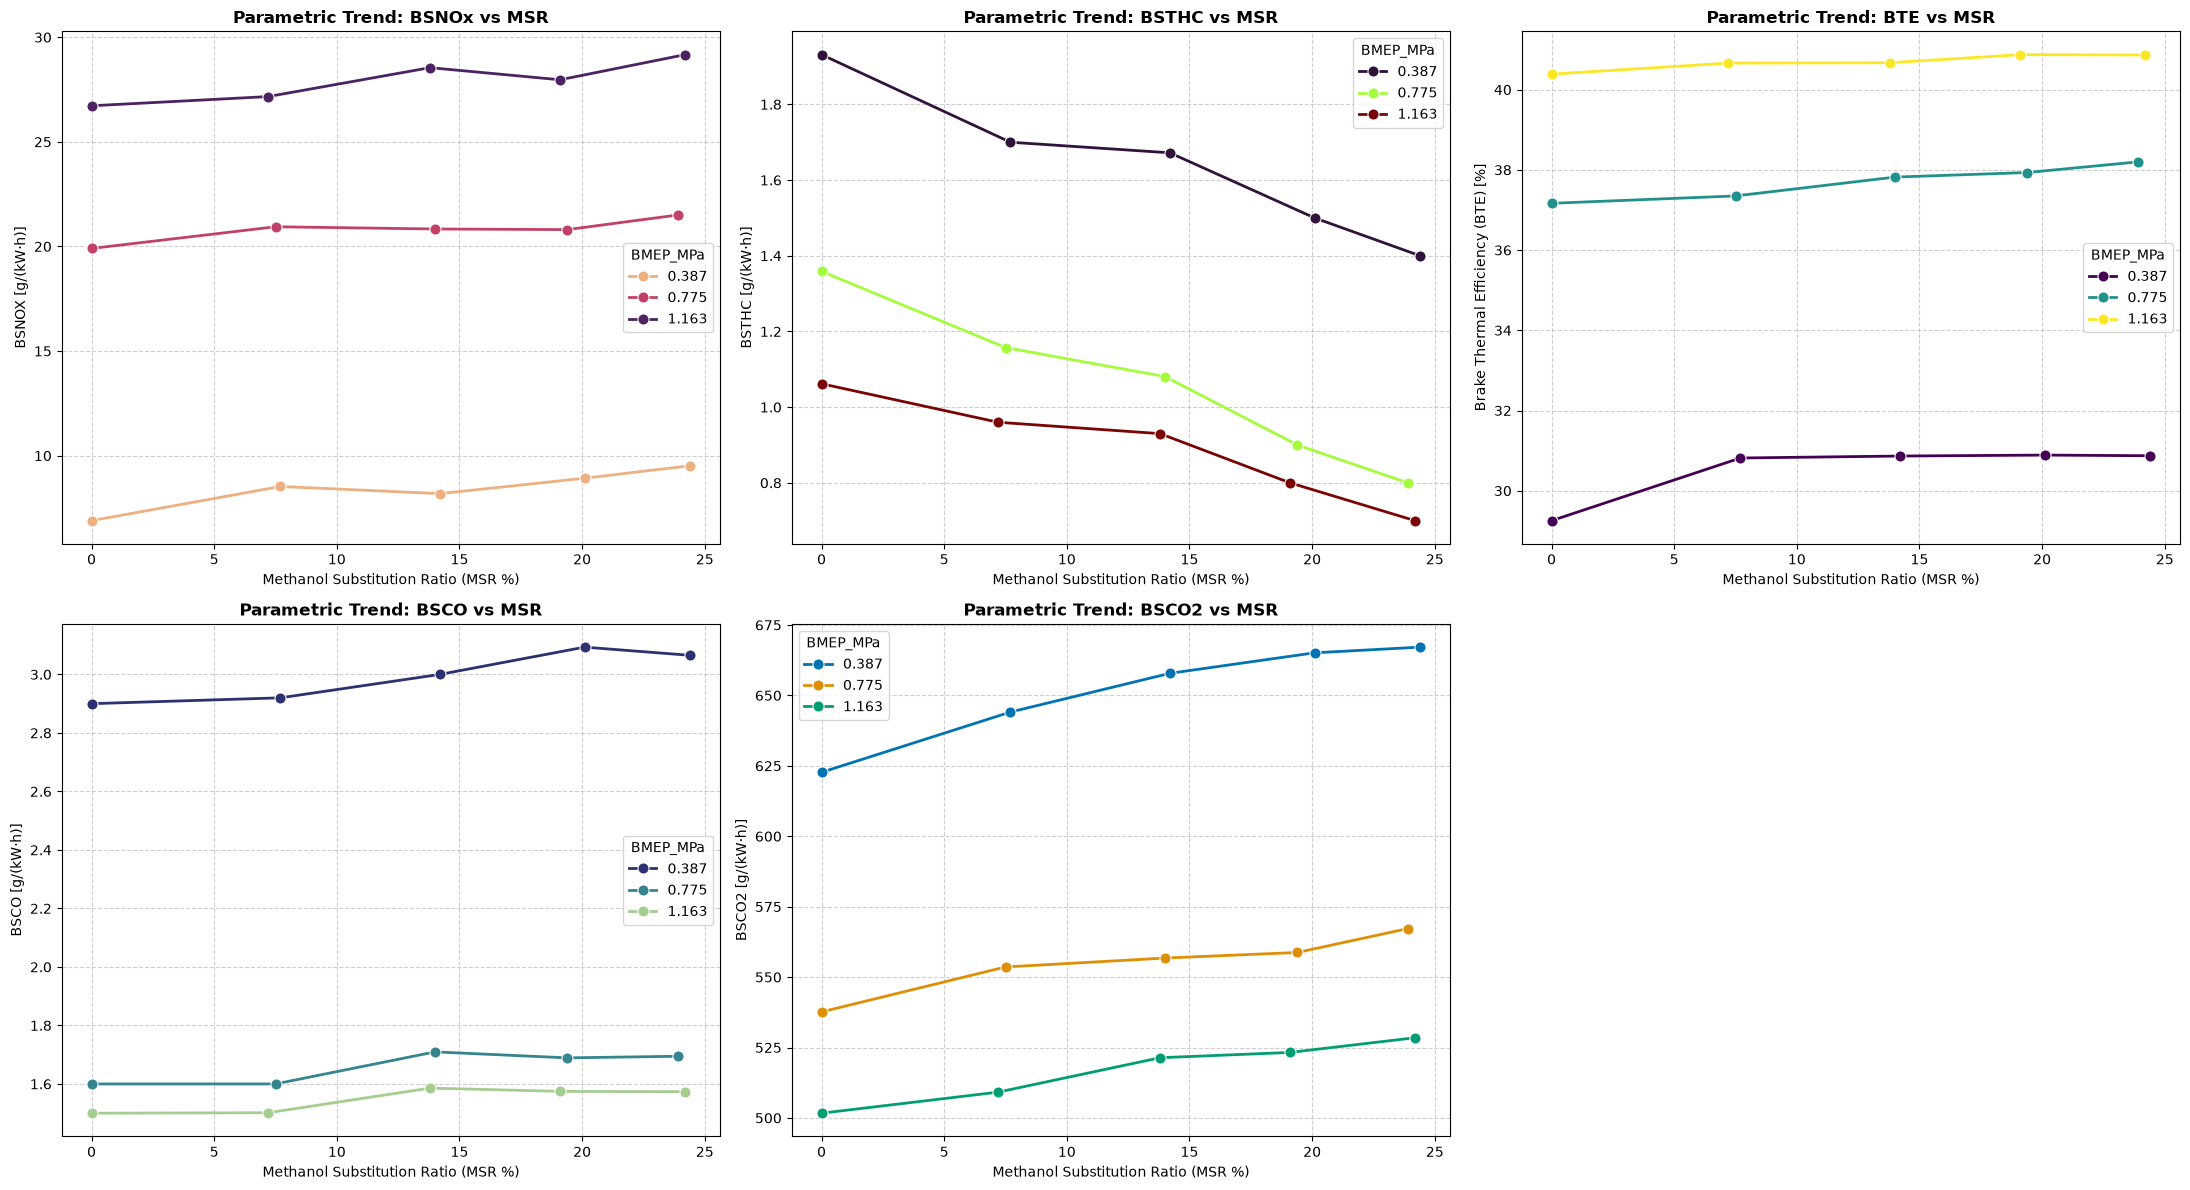

In [11]:
# visualizing the parametric trends
fig, axes = plt.subplots(2, 3, figsize=(22, 12), facecolor='white')

# Plot A (Top Left): NOx behavior
sns.lineplot(data=df_full, x='MSR_%', y='BSNOX', hue='BMEP_MPa', palette='flare', 
             marker='o', markersize=8, ax=axes[0, 0], linewidth=2)
axes[0, 0].set_title('Parametric Trend: BSNOx vs MSR', fontweight='bold')
axes[0, 0].set_ylabel('BSNOX [g/(kW·h)]')
axes[0, 0].set_xlabel('Methanol Substitution Ratio (MSR %)')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# Plot B (Top Middle): THC behavior
sns.lineplot(data=df_full, x='MSR_%', y='BSTHC', hue='BMEP_MPa', palette='turbo', 
             marker='o', markersize=8, ax=axes[0, 1], linewidth=2)
axes[0, 1].set_title('Parametric Trend: BSTHC vs MSR', fontweight='bold')
axes[0, 1].set_ylabel('BSTHC [g/(kW·h)]')
axes[0, 1].set_xlabel('Methanol Substitution Ratio (MSR %)')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Plot C (Top Right): BTE behavior
sns.lineplot(data=df_full, x='MSR_%', y='BTE', hue='BMEP_MPa', palette='viridis', 
             marker='o', markersize=8, ax=axes[0, 2], linewidth=2)
axes[0, 2].set_title('Parametric Trend: BTE vs MSR', fontweight='bold')
axes[0, 2].set_ylabel('Brake Thermal Efficiency (BTE) [%]')
axes[0, 2].set_xlabel('Methanol Substitution Ratio (MSR %)')
axes[0, 2].grid(True, linestyle='--', alpha=0.6)

# Plot D (Bottom Left): BSCO behavior
sns.lineplot(data=df_full, x='MSR_%', y='BSCO', hue='BMEP_MPa', palette='crest_r', 
             marker='o', markersize=8, ax=axes[1, 0], linewidth=2)
axes[1, 0].set_title('Parametric Trend: BSCO vs MSR', fontweight='bold')
axes[1, 0].set_ylabel('BSCO [g/(kW·h)]')
axes[1, 0].set_xlabel('Methanol Substitution Ratio (MSR %)')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# Plot E (Bottom Middle): BSCO2 behavior
sns.lineplot(data=df_full, x='MSR_%', y='BSCO2', hue='BMEP_MPa', palette='colorblind', 
             marker='o', markersize=8, ax=axes[1, 1], linewidth=2)
axes[1, 1].set_title('Parametric Trend: BSCO2 vs MSR', fontweight='bold')
axes[1, 1].set_ylabel('BSCO2 [g/(kW·h)]')
axes[1, 1].set_xlabel('Methanol Substitution Ratio (MSR %)')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

# removing the unused 6th subplot (Bottom Right)
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.savefig('result_images/eda_parametric_trends.png', dpi=300)
plt.show()
plt.close()

### #3 Data preparation, Model training and saving

In [12]:
# preparing the features (X) and targets (Y)
X = df_full[['BMEP_MPa', 'MSR_%']].values
targets = ['BSNOX', 'BSTHC', 'BSCO2', 'BTE']

In [32]:
# instantiating the model pool
models = {
    'Ridge': Ridge(alpha=0.1),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42),
    'Gaussian Process': GaussianProcessRegressor(kernel=C(1.0) * RBF(length_scale=1.0), n_restarts_optimizer=10, normalize_y=True, random_state=42)
}

In [14]:
# performing the Leave-One-Out Cross-Validation procedure
loo = LeaveOneOut()
tournament_results = []

print("Executing Leave-One-Out Cross-Validation (15 folds per target)...\n")
for target in targets:
    y = df_full[target].values
    
    for name, model in models.items():
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', model)
        ])
        
        y_pred = []
        for train_index, test_index in loo.split(X):
            X_train, X_test = X[train_index], X[test_index]
            y_train, y_test = y[train_index], y[test_index]
            
            pipeline.fit(X_train, y_train)
            pred = pipeline.predict(X_test)
            y_pred.append(pred[0])
            
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        tournament_results.append({'Target': target, 'Model': name, 'LOOCV_RMSE': rmse})

Executing Leave-One-Out Cross-Validation (15 folds per target)...



In [15]:
# determining the best models for each target variables
df_selection_process = pd.DataFrame(tournament_results)
idx = df_selection_process.groupby(['Target'])['LOOCV_RMSE'].transform(min) == df_selection_process['LOOCV_RMSE']
best_models = df_selection_process[idx].sort_values(by='Target')

print("--- LOOCV PROCESS BEST MODELS ---")
print(best_models.to_string(index=False))

--- LOOCV PROCESS BEST MODELS ---
Target             Model  LOOCV_RMSE
 BSCO2  Gaussian Process    7.712594
 BSNOX Gradient Boosting    0.679281
 BSTHC  Gaussian Process    0.083270
   BTE Gradient Boosting    0.457844


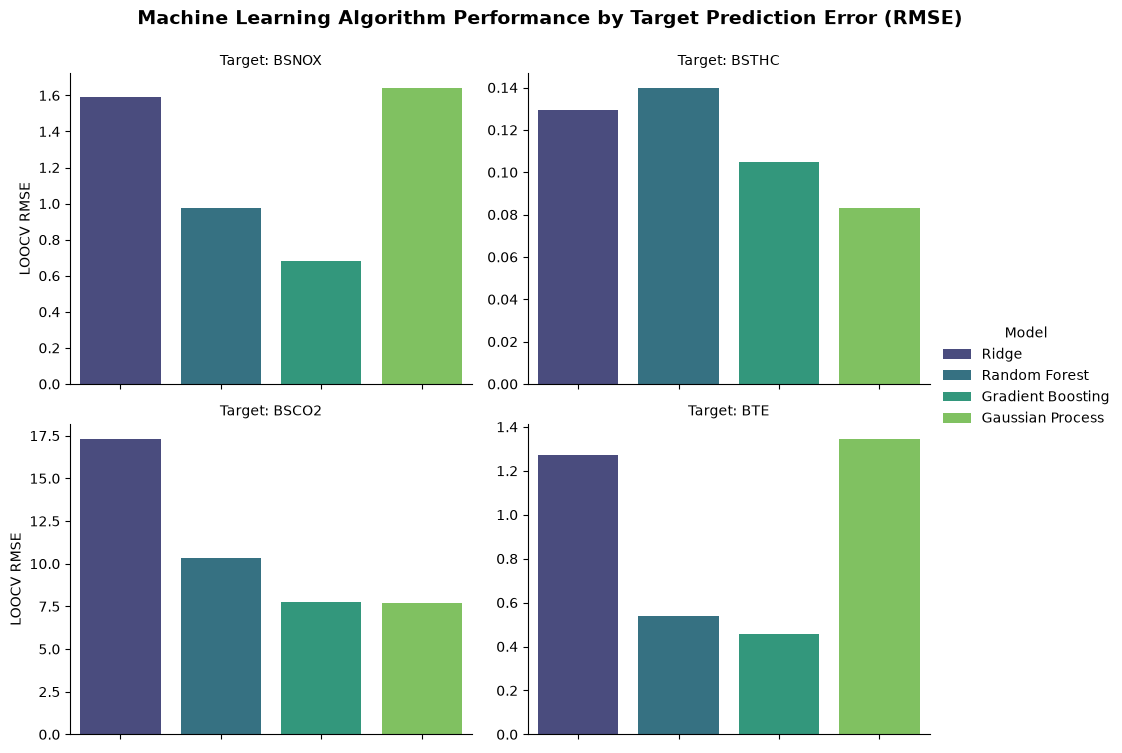

In [29]:
# creating a grid of bar charts
g = sns.catplot(
    data=df_selection_process,
    x='Model',
    y='LOOCV_RMSE',
    col='Target',
    col_wrap=2,          # creates a 2x2 grid for the 4 targets
    kind='bar',
    sharey=False,        # giving each chart its own independent Y-axis scale
    height=4,            # height of each subplot
    aspect=1.2,          # width-to-height ratio
    palette="viridis",
    hue="Model",          # color-code for the models
    legend=True
)

# rotating the X-axis labels
g.set_xticklabels(rotation=45, ha='right')

# setting up the axis titles
g.set_axis_labels("", "LOOCV RMSE")
g.set_titles("Target: {col_name}")

# Add a main title for the entire figure
g.fig.suptitle("Machine Learning Algorithm Performance by Target Prediction Error (RMSE)", fontsize=14, fontweight='bold')

g.fig.subplots_adjust(top=0.9)

# plt.tight_layout()
plt.savefig("result_images/model_performance_rmse.png", bbox_inches='tight', dpi=300)
plt.show()
plt.close()

In [33]:
# isolating the input features
X_full = df_full[['BMEP_MPa', 'MSR_%']].values

In [35]:
# instantiating the models chosen by the LOOCV 
final_architectures = {
    'BSCO2': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianProcessRegressor(kernel=C(1.0) * RBF(length_scale=1.0), n_restarts_optimizer=10, normalize_y=True, random_state=42))
    ]),
    'BSNOX': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42))
    ]),
    'BSTHC': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianProcessRegressor(kernel=C(1.0) * RBF(length_scale=1.0), n_restarts_optimizer=10, normalize_y=True, random_state=42))
    ]),
    'BTE': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42))
    ])
}

In [36]:
# training the ML models & exporting for Streamlit
trained_models = {}
print("training the final surrogate models...")
for target, pipeline in final_architectures.items():
    y_full = df_full[target].values
    pipeline.fit(X_full, y_full)
    trained_models[target] = pipeline
    
    # exporting the trained model
    joblib.dump(pipeline, f"trained_models/model_{target}.pkl")
    print(f" - {target} model trained and saved as model_{target}.pkl")

training the final surrogate models...
 - BSCO2 model trained and saved as model_BSCO2.pkl
 - BSNOX model trained and saved as model_BSNOX.pkl
 - BSTHC model trained and saved as model_BSTHC.pkl
 - BTE model trained and saved as model_BTE.pkl


### #4 Model Analysis & Pareto Optimization

In [37]:
# executing the multi-objective Pareto Optimization

# generating a dense grid of 10,000 theoretical engine operating points
bmep_range = np.linspace(0.387, 1.163, 100)
msr_range = np.linspace(0, 25, 100)
BMEP_grid, MSR_grid = np.meshgrid(bmep_range, msr_range)

# flattening the grid to feed into the models
X_simulated = np.c_[BMEP_grid.ravel(), MSR_grid.ravel()]

In [38]:
# predicting the NOX and Efficiency for all 10,000 untested coordinates
print("\nSimulating 10,000 operating points for Pareto Optimization...")
predicted_bsnox = trained_models['BSNOX'].predict(X_simulated)
predicted_bte = trained_models['BTE'].predict(X_simulated)


Simulating 10,000 operating points for Pareto Optimization...


In [39]:
# generating the continuous search space
bmep_range = np.linspace(0.387, 1.163, 100)
msr_range = np.linspace(0, 25, 100)
BMEP_grid, MSR_grid = np.meshgrid(bmep_range, msr_range)
X_continuous = np.c_[BMEP_grid.ravel(), MSR_grid.ravel()]

# predicting NOx and efficiency for the overall 10,000 point continuous map
pred_nox_cont = trained_models['BSNOX'].predict(X_continuous)
pred_bte_cont = trained_models['BTE'].predict(X_continuous)


In [41]:
# extracting the local pareto frontiers (optimal operating boundary) for specific loads
target_loads = [0.387, 0.775, 1.163]
local_frontiers = {}

for load in target_loads:
    # simulating 500 distinct MSR settings at this specific engine load
    msr_sweep = np.linspace(0, 25, 500)
    X_local = np.c_[np.full_like(msr_sweep, load), msr_sweep]
    
    local_nox = trained_models['BSNOX'].predict(X_local)
    local_bte = trained_models['BTE'].predict(X_local)
    
    df_local = pd.DataFrame({'BSNOX': local_nox, 'BTE': local_bte})
    df_local = df_local.sort_values('BSNOX', ascending=True)
    
    front_x = []
    front_y = []
    max_bte_seen = -np.inf
    
    # identifying non-dominated points strictly within this specific load profile
    for _, row in df_local.iterrows():
        if row['BTE'] > max_bte_seen:
            front_x.append(row['BSNOX'])
            front_y.append(row['BTE'])
            max_bte_seen = row['BTE']
            
    local_frontiers[load] = (front_x, front_y)

Localized Pareto Frontiers extracted and plotted successfully.


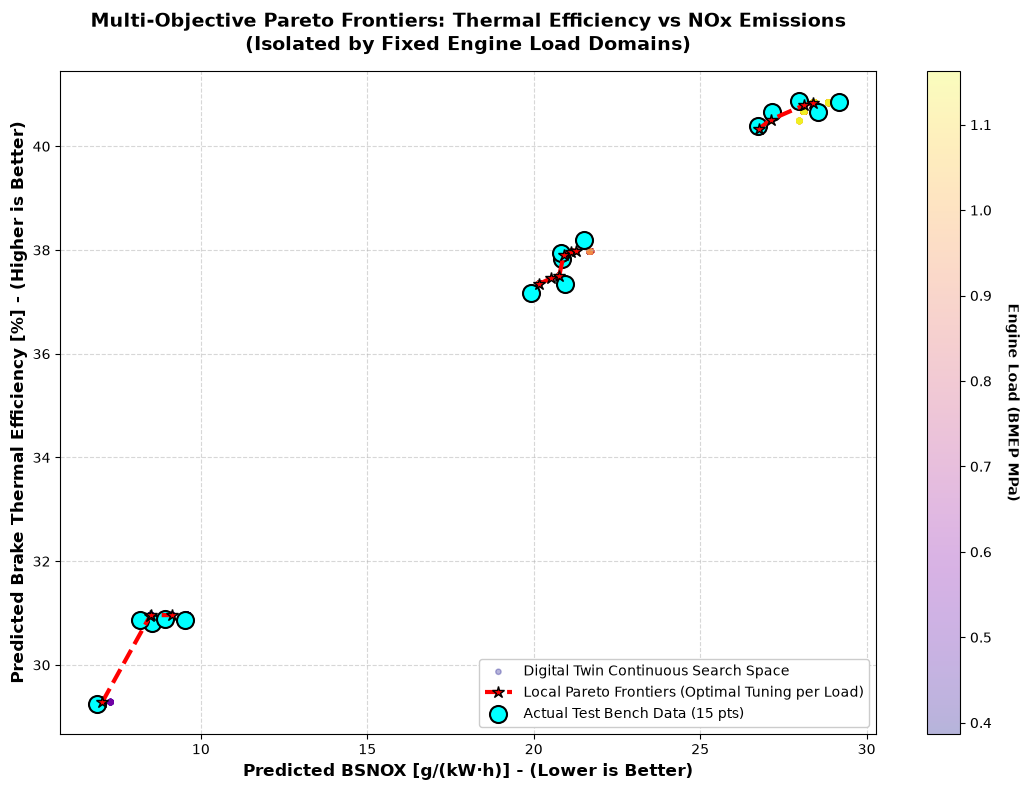

In [44]:
# visualizing the pareto frontiers for the different engine loads
plt.figure(figsize=(11, 8), facecolor='white')

# scattering the continuous search space (in the background) 
sc = plt.scatter(pred_nox_cont, pred_bte_cont, c=X_continuous[:, 0], cmap='plasma', 
                 alpha=0.3, s=15, label='Digital Twin Continuous Search Space')

# plotting the three physically isolated local Pareto Frontiers
for idx, (load, (fx, fy)) in enumerate(local_frontiers.items()):
    # Only label the first one to keep the legend clean
    label = 'Local Pareto Frontiers (Optimal Tuning per Load)' if idx == 0 else ""
    plt.plot(fx, fy, color='red', linestyle='--', linewidth=3, 
             marker='*', markersize=9, markeredgecolor='black', zorder=10, label=label)

# overlaying the 15 actual physical test points
plt.scatter(df_full['BSNOX'], df_full['BTE'], color='cyan', edgecolors='black', 
            linewidths=1.5, s=150, zorder=5, label='Actual Test Bench Data (15 pts)')

plt.title('Multi-Objective Pareto Frontiers: Thermal Efficiency vs NOx Emissions\n(Isolated by Fixed Engine Load Domains)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted BSNOX [g/(kW·h)] - (Lower is Better)', fontsize=12, fontweight='bold')
plt.ylabel('Predicted Brake Thermal Efficiency [%] - (Higher is Better)', fontsize=12, fontweight='bold')

cbar = plt.colorbar(sc)
cbar.set_label('Engine Load (BMEP MPa)', rotation=270, labelpad=20, fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=10, framealpha=1.0)
plt.tight_layout()

plt.savefig('result_images/localized_pareto_frontier.png', dpi=300)
print("Localized Pareto Frontiers extracted and plotted successfully.")

plt.show()